# Data quality and exploratory analysis
Research question: what can the available football observations support? Audit the source mix before analyzing rates. Raw legacy files are preserved, including excluded synthetic rows. This notebook analyses only the explicitly labelled subset, not a validated six-season dataset.

In [1]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd()
while not (ROOT / 'src/config.py').exists():
    if ROOT == ROOT.parent: raise RuntimeError('Run inside the project')
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLCONFIGDIR', '/tmp/tfm-matplotlib')
os.environ.setdefault('XDG_CACHE_HOME', '/tmp/tfm-cache')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from src.config import ROOT, MODELS_DIR
from src.preprocessing.clean import load_players
players = load_players()
dataset = json.loads((ROOT / 'reports/dataset.json').read_text())
display(Markdown('**Dataset:** ' + dataset['dataset_kind'] + '. Legacy-labelled observations are preliminary; no synthetic rows are included.'))
assert not players.source.str.contains('demo|synthetic', case=False).any()


**Dataset:** real_legacy_unverified. Legacy-labelled observations are preliminary; no synthetic rows are included.

In [2]:
raw = pd.read_csv(ROOT / 'data/raw/players_raw.csv')
display(raw.groupby(['source','league','season']).size().rename('raw_rows').to_frame())
coverage = pd.read_csv(ROOT / 'reports/source_coverage.csv')
display(coverage.groupby(['source','status']).size().rename('coverage_cells').to_frame())
display(players.groupby(['league','season','pos_main']).agg(observations=('player_id','size'),minutes=('minutes','sum')))
print('Rows after conservative minutes/transfer handling:', len(players))
print('Conflicting/duplicate processed observation IDs:', players.player_id.duplicated().sum())


raw_rows
source      league  season          
demo        La Liga 2223         180
                    2425         180
            Segunda 2223         240
                    2425         240
fbref_cache La Liga 2324         609

coverage_cells
source        status                               
fbref         blocked                            72
transfermarkt historical_unverified              60
understat     blocked                             6
              unavailable                         6

observations   minutes
league  season    pos_main                        
La Liga 2023-2024 DF                 156  272021.0
                  FW                  64  103154.0
                  GK                  27   64795.0
                  MF                 173  280238.0

Rows after conservative minutes/transfer handling: 420
Conflicting/duplicate processed observation IDs: 0


## Missingness and preprocessing
Unavailable source statistics remain missing, not zero. Training-time median imputation only applies to selected partially observed features. All-missing columns are excluded. Legacy shots and defensive statistics are discarded because the original merge used row order. Per-90 rates use exact minutes/90, rather than rounded published 90s. No market values are estimated from age or production.

,missing_fraction
tklw_p90,1.0
sh_p90,1.0
crs_p90,1.0
sot_p90,1.0
int_p90,1.0
age,0.0
minutes,0.0
ga_p90,0.0
gls_p90,0.0
ast_p90,0.0


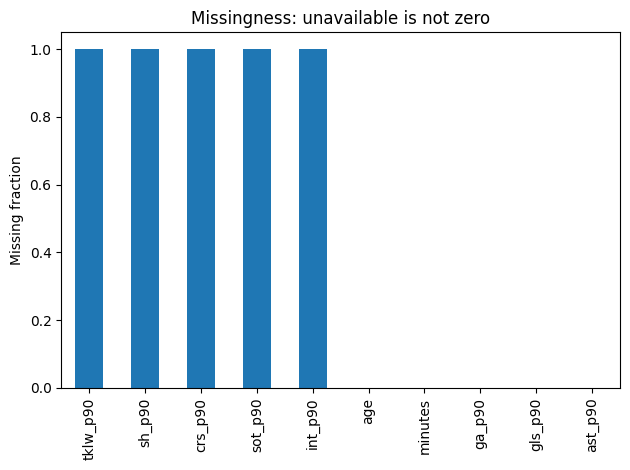

,count,mean,std,min,25%,50%,75%,max
age,420.0,26.552381,4.418946,16.0,23.000000,26.000000,30.000000,40.000000
minutes,420.0,1714.780952,778.080009,459.0,1050.500000,1649.500000,2356.750000,3420.000000
gls_p90,420.0,0.118355,0.166353,0.0,0.000000,0.059703,0.163138,1.007463
ast_p90,420.0,0.086080,0.100374,0.0,0.000000,0.058084,0.138756,0.592105
ga_p90,420.0,0.204435,0.219277,0.0,0.039331,0.137300,0.294481,1.343284
sh_p90,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sot_p90,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
int_p90,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tklw_p90,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
crs_p90,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
numeric = ['age','minutes','gls_p90','ast_p90','ga_p90','sh_p90','sot_p90','int_p90','tklw_p90','crs_p90']
missing = players[numeric].isna().mean().sort_values(ascending=False)
display(missing.rename('missing_fraction').to_frame())
missing.plot.bar(title='Missingness: unavailable is not zero'); plt.ylabel('Missing fraction'); plt.tight_layout(); plt.show()
display(players[numeric].describe().T)


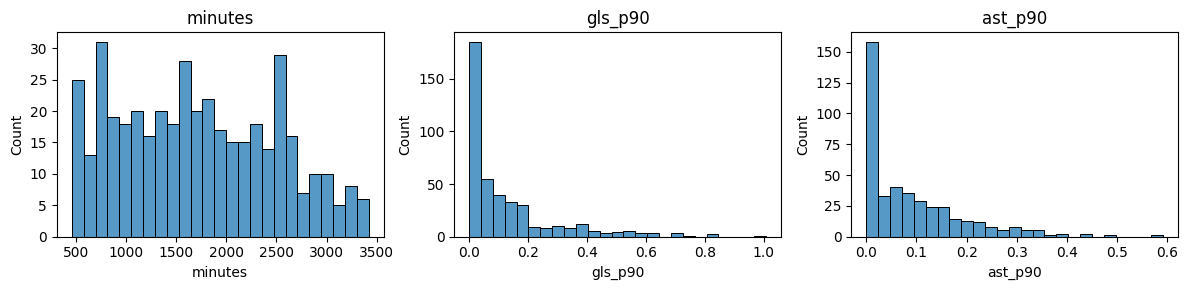

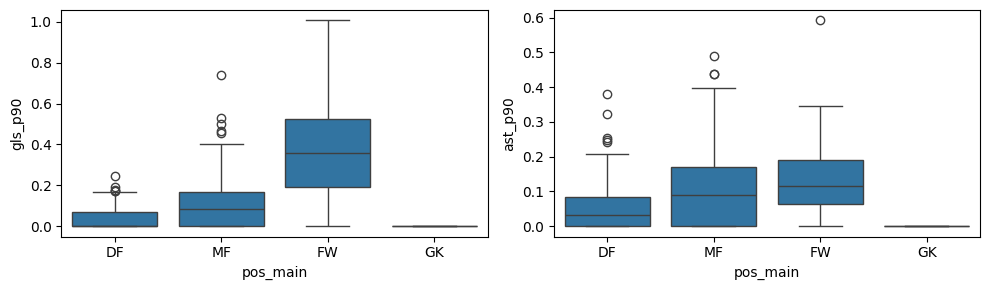

,player,minutes,gls_p90,sh_p90


Flagged extreme observations: 0


In [4]:
fig,axes=plt.subplots(1,3,figsize=(12,3))
for ax,col in zip(axes,['minutes','gls_p90','ast_p90']):
    sns.histplot(players[col].dropna(),ax=ax,bins=25); ax.set_title(col)
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(10,3))
for ax,col in zip(axes,['gls_p90','ast_p90']):
    sns.boxplot(data=players,x='pos_main',y=col,ax=ax)
plt.tight_layout();plt.show()
display(players[players.quality_outlier][['player','minutes','gls_p90','sh_p90']])
print('Flagged extreme observations:', int(players.quality_outlier.sum()))


Extreme observations are flagged for source review rather than silently clipped. The 450-minute eligibility floor limits the most unstable rate estimates, but does not establish reliability or remove selection bias. Position comparisons are descriptive; leagues and seasons cannot be compared if only one is available.

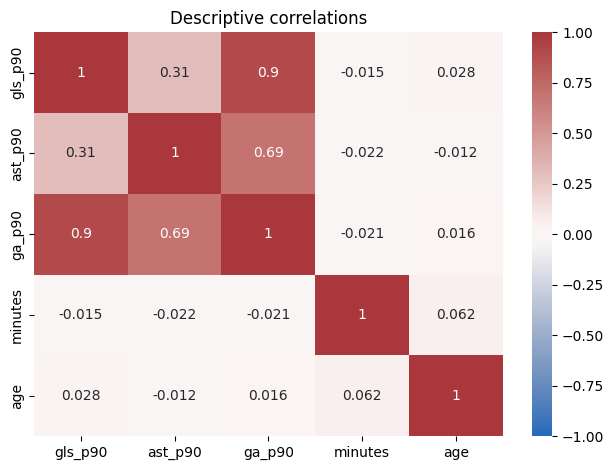

gls_p90         ast_p90      
            median count    median count
pos_main                                
DF        0.000000   156  0.033262   156
FW        0.360624    64  0.117078    64
GK        0.000000    27  0.000000    27
MF        0.085796   173  0.090909   173

,,gls_p90,ast_p90
league,season,,
La Liga,2023-2024,0.059703,0.058084


Available leagues: **1**; seasons: **1**. Cross-league and temporal conclusions are blocked. G+A is algebraically redundant with goals and assists, so it is excluded from model fitting.

In [5]:
corr=players[['gls_p90','ast_p90','ga_p90','minutes','age']].corr()
sns.heatmap(corr,annot=True,vmin=-1,vmax=1,cmap='vlag');plt.title('Descriptive correlations');plt.tight_layout();plt.show()
display(players.groupby('pos_main')[['gls_p90','ast_p90']].agg(['median','count']))
display(players.groupby(['league','season'])[['gls_p90','ast_p90']].median())
display(Markdown(f'Available leagues: **{players.league.nunique()}**; seasons: **{players.season.nunique()}**. Cross-league and temporal conclusions are blocked. G+A is algebraically redundant with goals and assists, so it is excluded from model fitting.'))


## Separate current Transfermarkt sample
The source league-page sample is a top-value first-page selection, not a representative roster. Current valuations cannot backfill 2020–2026 decision dates. The requested season parameter is retained solely as provenance, not as a verified effective season.

,rows,missing_value
league,,
La Liga,25,0
Segunda,25,0


,player,league,market_value_eur,valuation_date,temporal_scope
0,Lamine Yamal,La Liga,220000000,NaN,current_snapshot_not_historical
1,Kylian Mbappé,La Liga,200000000,NaN,current_snapshot_not_historical
2,Jude Bellingham,La Liga,160000000,NaN,current_snapshot_not_historical
3,Pedri,La Liga,150000000,NaN,current_snapshot_not_historical
4,Vinicius Junior,La Liga,130000000,NaN,current_snapshot_not_historical


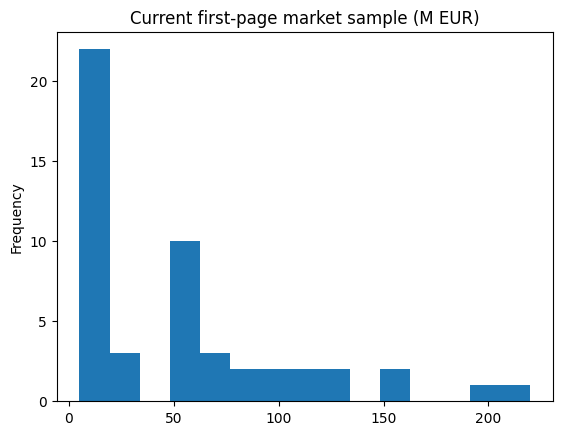

In [6]:
tm_path=ROOT/'data/external/transfermarkt/current_market_sample.csv'
if tm_path.exists():
    tm=pd.read_csv(tm_path)
    display(tm.groupby('league').agg(rows=('source_player_id','size'),missing_value=('market_value_eur',lambda x:x.isna().sum())))
    display(tm[['player','league','market_value_eur','valuation_date','temporal_scope']].head())
    tm['market_value_eur'].dropna().div(1e6).plot.hist(bins=15,title='Current first-page market sample (M EUR)');plt.show()
else:
    display(Markdown('No parsed Transfermarkt sample available.'))


## Interpretation
The data supports preliminary descriptions of attacking output and availability only. Missing defensive/passing metrics prevent broad tactical-style interpretation. The legacy provenance and single-season restriction prevent a final TFM claim about recommendation quality. New source snapshots or licensed exports with stable IDs and dated valuations are required.